In [3]:
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

def Euler(F, U, t, h):
  return U + h * F(U, t)


def Inverse_Euler(F, U, t, h):
  def residual(U_next):
    return U_next - U - h * F(U_next, t + h)

  U_guess = Euler(F, U, t, h)
  U_next = fsolve(residual, U_guess)
  return U_next if U_next.size > 1 else U_next[0]


def Crank_Nicolson(F, U, t, h):
  def residual(U_next):
    return U_next - U - (h / 2.0) * (F(U, t) + F(U_next, t + h))

  U_guess = Euler(F, U, t, h)
  U_next = fsolve(residual, U_guess)
  return U_next if U_next.size > 1 else U_next[0]


def RK4(F, U, t, h):
  k1 = F(U, t)
  k2 = F(U + 0.5 * h * k1, t + 0.5 * h)
  k3 = F(U + 0.5 * h * k2, t + 0.5 * h)
  k4 = F(U + h * k3, t + h)
  return U + (h / 6.0) * (k1 + 2.0 * k2 + 2.0 * k3 + k4)


1. INTEGRACIÓN DE PROBLEMA LINEAL

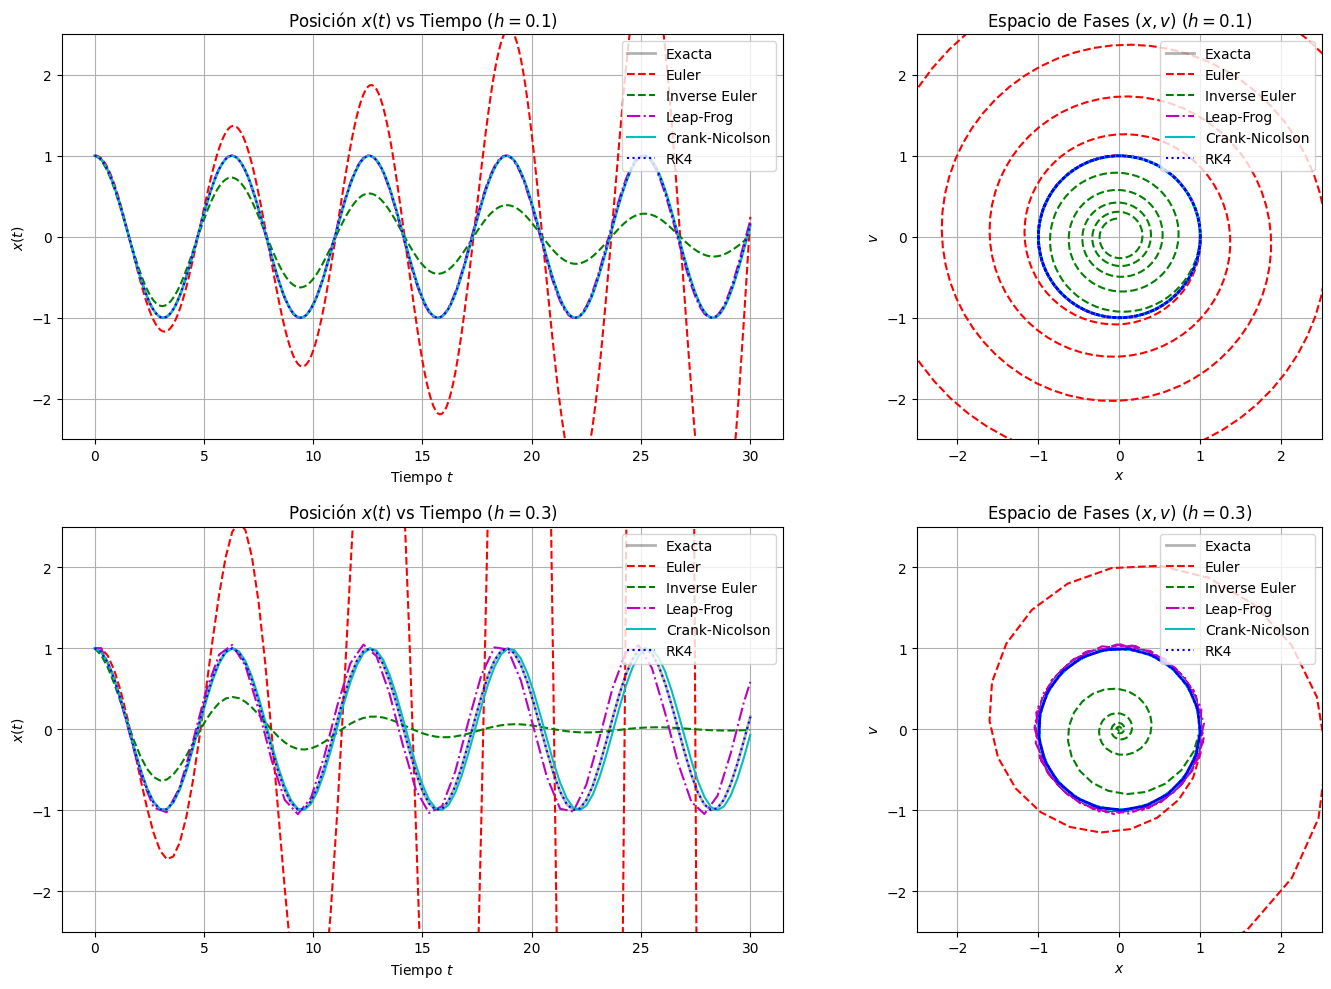

In [4]:

def Leap_Frog(F, U_prev, U_curr, t, h):
  """Esquema Leap-Frog (punto medio de 2 pasos)."""
  return U_prev + 2.0 * h * F(U_curr, t)


def integrate_cauchy(scheme, F, U0, t_array):
  """Integra un problema de Cauchy soportando esquemas de 1 paso y Leap-Frog (2 pasos)."""
  num_steps = len(t_array)
  if isinstance(U0, (int, float)):
    U = np.zeros(num_steps)
  else:
    U = np.zeros((num_steps, len(U0)))

  U[0] = U0

  # Caso especial para Leap-Frog (requiere dos instantes previos)
  if scheme == Leap_Frog:
    h0 = t_array[1] - t_array[0]
    # Arrancamos el primer paso con Euler (o RK4)
    U[1] = Euler(F, U[0], t_array[0], h0)
    for i in range(1, num_steps - 1):
      t = t_array[i]
      h = t_array[i + 1] - t_array[i]
      U[i + 1] = Leap_Frog(F, U[i - 1], U[i], t, h)
  else:
    # Esquemas de un solo paso
    for i in range(num_steps - 1):
      t = t_array[i]
      h = t_array[i + 1] - t_array[i]
      U[i + 1] = scheme(F, U[i], t, h)

  return U


# ==========================================
# PROBLEMA LINEAL: OSCILADOR ARMÓNICO (x'' + x = 0)
# ==========================================
def linear_oscillator_F(U, t=0):
  """Sistema lineal: U = [x, v], dU/dt = [v, -x].

  Autovalores de la matriz del sistema: lambda = +i, -i (eje imaginario puro).
  """
  x, v = U[0], U[1]
  return np.array([v, -x])


# Condiciones iniciales y parámetros de simulación
U0 = np.array([1.0, 0.0])
t_final = 30.0
pasos_h = [0.1, 0.3]  # Probamos dos pasos de tiempo

esquemas = [
    ("Euler", Euler, "r--"),
    ("Inverse Euler", Inverse_Euler, "g--"),
    ("Leap-Frog", Leap_Frog, "m-."),
    ("Crank-Nicolson", Crank_Nicolson, "c-"),
    ("RK4", RK4, "b:"),
]

fig, axs = plt.subplots(2, 2, figsize=(15, 10))

for idx, h in enumerate(pasos_h):
  t_array = np.arange(0, t_final + h, h)

  # Solución analítica exacta: x(t) = cos(t), v(t) = -sin(t)
  axs[idx, 0].plot(t_array, np.cos(t_array), "k-", lw=2, alpha=0.3, label="Exacta")
  axs[idx, 1].plot(
      np.cos(t_array), -np.sin(t_array), "k-", lw=2, alpha=0.3, label="Exacta"
  )

  for nombre, esquema, estilo in esquemas:
    U_sol = integrate_cauchy(esquema, linear_oscillator_F, U0, t_array)

    # Evolución temporal x(t)
    axs[idx, 0].plot(t_array, U_sol[:, 0], estilo, lw=1.5, label=nombre)
    # Diagrama de fases (x vs v)
    axs[idx, 1].plot(U_sol[:, 0], U_sol[:, 1], estilo, lw=1.5, label=nombre)

  axs[idx, 0].set_title(f"Posición $x(t)$ vs Tiempo ($h = {h}$)")
  axs[idx, 0].set_xlabel("Tiempo $t$")
  axs[idx, 0].set_ylabel("$x(t)$")
  axs[idx, 0].set_ylim(-2.5, 2.5)
  axs[idx, 0].grid(True)
  axs[idx, 0].legend(loc="upper right")

  axs[idx, 1].set_title(f"Espacio de Fases $(x, v)$ ($h = {h}$)")
  axs[idx, 1].set_xlabel("$x$")
  axs[idx, 1].set_ylabel("$v$")
  axs[idx, 1].set_xlim(-2.5, 2.5)
  axs[idx, 1].set_ylim(-2.5, 2.5)
  axs[idx, 1].set_aspect("equal")
  axs[idx, 1].grid(True)
  axs[idx, 1].legend(loc="upper right")

plt.tight_layout()
plt.show()


2. REGIONES DE ESTABILIDAD

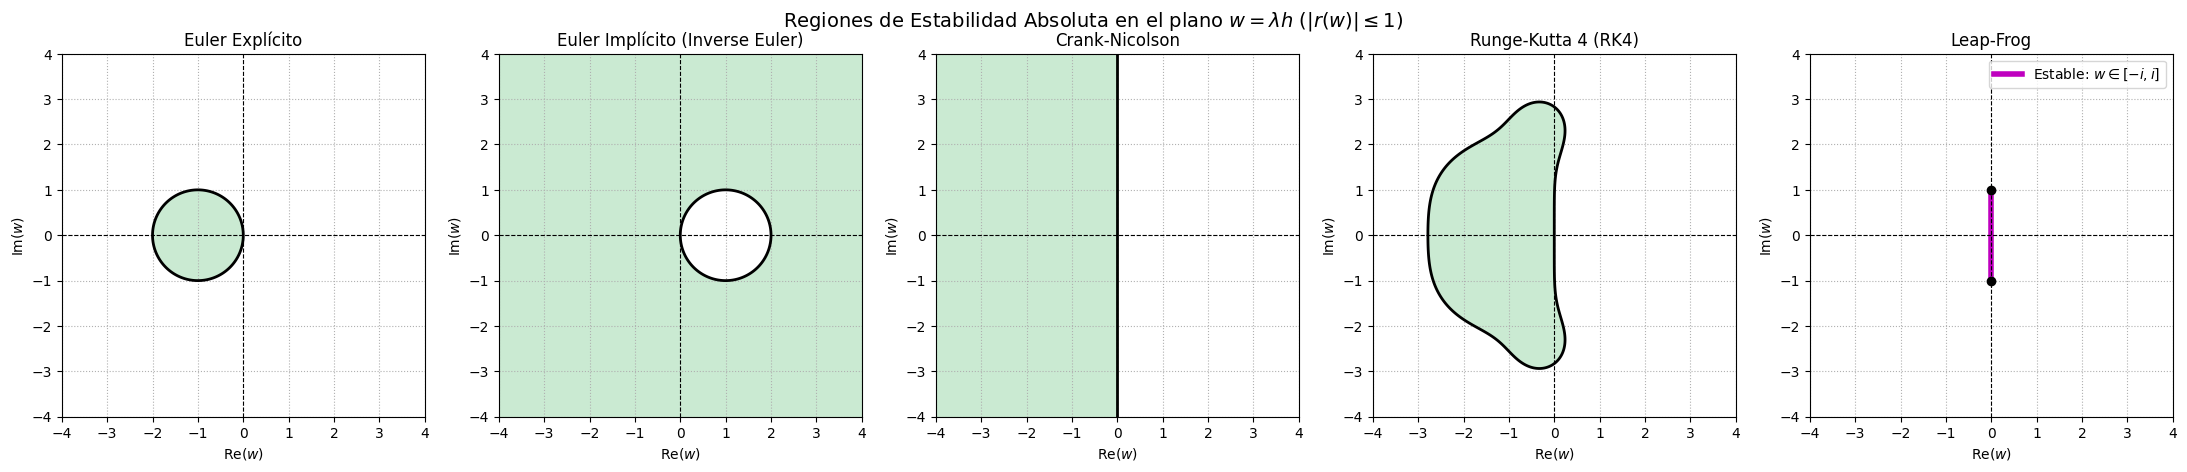

In [5]:

def plot_stability_regions():
  # Malla en el plano complejo w = Re(w) + i*Im(w), donde w = lambda * h
  x = np.linspace(-4, 4, 500)
  y = np.linspace(-4, 4, 500)
  X, Y = np.meshgrid(x, y)
  W = X + 1j * Y

  # Factores de amplificación |r(w)| para los métodos de 1 paso
  R_euler = np.abs(1.0 + W)
  R_inv_euler = np.abs(1.0 / (1.0 - W))
  R_cn = np.abs((1.0 + 0.5 * W) / (1.0 - 0.5 * W))
  R_rk4 = np.abs(1.0 + W + (W**2) / 2.0 + (W**3) / 6.0 + (W**4) / 24.0)

  # Polinomio característico de Leap-Frog: r^2 - 2*w*r - 1 = 0 -> raíces r = w +- sqrt(w^2 + 1)
  r1_lf = W + np.sqrt(W**2 + 1.0)
  r2_lf = W - np.sqrt(W**2 + 1.0)
  R_lf = np.maximum(np.abs(r1_lf), np.abs(r2_lf))

  metodos_1paso = [
      ("Euler Explícito", R_euler, "Reds"),
      ("Euler Implícito (Inverse Euler)", R_inv_euler, "Greens"),
      ("Crank-Nicolson", R_cn, "Blues"),
      ("Runge-Kutta 4 (RK4)", R_rk4, "Purples"),
  ]

  fig, axs = plt.subplots(1, 5, figsize=(22, 4.5))

  # Graficamos los métodos de 1 paso
  for i, (titulo, R, cmap) in enumerate(metodos_1paso):
    # Sombreamos la región estable (|R| <= 1)
    axs[i].contourf(X, Y, R, levels=[0, 1], colors=["#a8ddb5"], alpha=0.6)
    # Frontera de estabilidad (|R| = 1)
    axs[i].contour(X, Y, R, levels=[1], colors=["k"], linewidths=2)

    axs[i].axhline(0, color="k", lw=0.8, ls="--")
    axs[i].axvline(0, color="k", lw=0.8, ls="--")
    axs[i].set_title(titulo)
    axs[i].set_xlabel(r"$\mathrm{Re}(w)$")
    axs[i].set_ylabel(r"$\mathrm{Im}(w)$")
    axs[i].set_aspect("equal")
    axs[i].grid(True, ls=":")

  # Graficamos Leap-Frog por separado (su región es el segmento imaginario [-i, i])
  axs[4].contour(X, Y, R_lf, levels=[1.001], colors=["gray"], linestyles="--")
  axs[4].plot(
      [0, 0], [-1, 1], color="m", lw=4, label=r"Estable: $w \in [-i, i]$"
  )
  axs[4].scatter([0, 0], [-1, 1], color="k", zorder=5)
  axs[4].axhline(0, color="k", lw=0.8, ls="--")
  axs[4].axvline(0, color="k", lw=0.8, ls="--")
  axs[4].set_title("Leap-Frog")
  axs[4].set_xlabel(r"$\mathrm{Re}(w)$")
  axs[4].set_ylabel(r"$\mathrm{Im}(w)$")
  axs[4].set_xlim(-4, 4)
  axs[4].set_ylim(-4, 4)
  axs[4].set_aspect("equal")
  axs[4].grid(True, ls=":")
  axs[4].legend(loc="upper right")

  plt.suptitle(
      r"Regiones de Estabilidad Absoluta en el plano $w = \lambda h$"
      r" ($|r(w)| \leq 1$)",
      fontsize=14,
  )
  plt.tight_layout()
  plt.show()


plot_stability_regions()

3. EXPLICACIÓN
